## Discovery of Neptune

### News:

Night of September 23-24, 1846. 

On the night of Sept. 23-24, 1846, astronomers discovered Neptune, the eighth planet orbiting around the Sun. The discovery was made based on mathematical calculations of its predicted position due to observed perturbations in the orbit of the planet Uranus. The discovery was made using a telescope since Neptune is too faint to be visible to the naked eye, owing to its great distance from the Sun.

With the 1781 discovery of Uranus, the number of known planets in the solar system grew to seven. As astronomers continued to observe the newly discovered planet, they noticed irregularities in its orbit that Newton’s law of universal gravitation could not fully explain.

### Perturbation Theory

Perturbation theory uses mathematical methods to approximate solutions to problems that cannot be solved exactly, starting from the exact solution of a simpler related case. For example, the orbit of a planet around the Sun can be treated as a two body problem, while the influence of other planets is considered a perturbation that causes variations in eccentricity, orbital plane oscillations, or the precision of the perihelion.

These variations matched observations for all planets except for Mercury, whose perihelion advanced more than predicted. This anomaly was first attributed to a hypothetical planet near the Sun but was later explained by Einstein's theory of relativity.



https://www.nasa.gov/history/175-years-ago-astronomers-discover-neptune-the-eighth-planet/

https://www.historyofinformation.com/detail.php?id=4004

https://arxiv.org/html/2405.06310v1#S2



Celestial Mechanics greatly motivated the advances of perturbation
 theories as witnessed by the discovery of Neptune: its position was theoretically predicted by
 John Adams and by Jean Urbain Leverrier on the basis of perturbative computations; following
 the suggestion provided by the theoretical investigations, Neptune was finally discovered on 23
 September 1846 by the astronomer Johann Gottfried Galle.

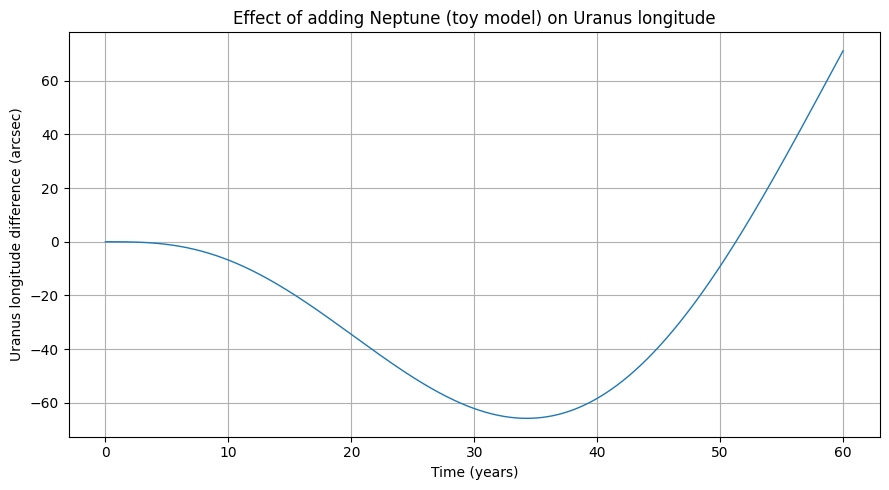

Saved residuals.png (toy model). Peak residual (arcsec): 71.1132783744045


In [1]:
"""
neptune_demo.py
Simple symplectic N-body demo to show Uranus longitude residuals caused by Neptune.
Usage: python neptune_demo.py
Outputs: residuals.png and data files.
"""

import numpy as np
import matplotlib.pyplot as plt

# Physical constants
G = 6.67430e-11           # m^3 kg^-1 s^-2
AU = 1.495978707e11       # m
DAY = 86400.0
yr = 365.25*DAY

# Masses (kg)
M_sun = 1.98847e30
m_jup = 1.89813e27
m_sat = 5.6834e26
m_ura = 8.6810e25
m_nep = 1.02413e26

# Semi-major axes (AU) (approx)
a_jup = 5.2044
a_sat = 9.5826
a_ura = 19.201
a_nep = 30.047

# Convert to meters
masses_base = {
    'Sun': M_sun,
    'Jupiter': m_jup,
    'Saturn': m_sat,
    'Uranus': m_ura,
    'Neptune': m_nep
}
a_base = {
    'Jupiter': a_jup*AU,
    'Saturn': a_sat*AU,
    'Uranus': a_ura*AU,
    'Neptune': a_nep*AU
}

def circular_velocity(mu, a):
    return np.sqrt(mu/a)

def init_system(include_neptune=True):
    # Order bodies: Sun, Jupiter, Saturn, Uranus, (Neptune)
    bodies = ['Sun','Jupiter','Saturn','Uranus']
    if include_neptune:
        bodies.append('Neptune')
    N = len(bodies)
    m = np.array([masses_base[name] for name in bodies])
    pos = np.zeros((N,3))
    vel = np.zeros((N,3))
    # Put Sun at origin; place planets on x-axis at t=0, velocities in +y for circular motion.
    pos[0,:] = 0.0
    for i,name in enumerate(bodies[1:], start=1):
        r = a_base[name]
        pos[i,0] = r
        mu = G*(M_sun + masses_base[name])  # approx
        v = circular_velocity(mu, r)
        vel[i,1] = v
        # Give Sun recoil so total momentum = 0
        vel[0] -= (m[i]/m[0]) * vel[i]
    return bodies, m, pos, vel

def accelerations(positions, masses):
    N = len(masses)
    a = np.zeros_like(positions)
    for i in range(N):
        for j in range(N):
            if i == j: continue
            rvec = positions[j] - positions[i]
            r = np.linalg.norm(rvec)
            a[i] += G * masses[j] * rvec / (r**3 + 1e-30)
    return a

def leapfrog_step(pos, vel, masses, dt):
    # kick-drift-kick (velocity Verlet form)
    a = accelerations(pos, masses)
    vel_half = vel + 0.5*dt*a
    pos_new = pos + dt*vel_half
    a_new = accelerations(pos_new, masses)
    vel_new = vel_half + 0.5*dt*a_new
    return pos_new, vel_new

def orbital_longitude(vec):
    # longitude in plane: atan2(y,x)
    return np.arctan2(vec[1], vec[0])

def run_sim(include_neptune, Tyears=50.0, dt_days=5.0):
    bodies, m, pos, vel = init_system(include_neptune=include_neptune)
    dt = dt_days * DAY
    steps = int(Tyears*yr/dt)
    times = np.linspace(0, Tyears*yr, steps)
    idx_ura = bodies.index('Uranus')
    lon = np.zeros(steps)
    for k in range(steps):
        lon[k] = orbital_longitude(pos[idx_ura])
        pos, vel = leapfrog_step(pos, vel, m, dt)
    # unwrap longitudes to be continuous
    lon = np.unwrap(lon)
    return times/yr, lon, bodies

if True:
    # Run both sims
    Tyears = 60.0
    times1, lon_no_nep, bodies1 = run_sim(include_neptune=False, Tyears=Tyears, dt_days=3.0)
    times2, lon_with_nep, bodies2 = run_sim(include_neptune=True, Tyears=Tyears, dt_days=3.0)

    # Interpolate to common timegrid (they share same grid here)
    residual = lon_with_nep - lon_no_nep

    # Convert residual (radians) to arcseconds:
    residual_arcsec = residual * (180.0/np.pi) * 3600.0

    plt.figure(figsize=(9,5))
    plt.plot(times1, residual_arcsec, lw=1)
    plt.xlabel("Time (years)")
    plt.ylabel("Uranus longitude difference (arcsec)")
    plt.title("Effect of adding Neptune (toy model) on Uranus longitude")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("residuals.png", dpi=150)
    plt.show()
    print("Saved residuals.png (toy model). Peak residual (arcsec):", np.max(np.abs(residual_arcsec)))


In [4]:
# discovery_orbits.py
import rebound
from astroquery.jplhorizons import Horizons
import numpy as np
import matplotlib.pyplot as plt

def get_orbit(name, epoch):
    """Safely fetch orbital elements from JPL Horizons"""
    obj = Horizons(id=name, location='@sun', epochs=epoch, id_type='majorbody')
    try:
        el = obj.elements()
    except Exception as e:
        print(f"Warning: Could not retrieve elements for {name}: {e}")
        return None
    return el

epoch = 2451545.0  # J2000.0 epoch

# Create REBOUND simulation
sim = rebound.Simulation()
sim.units = ('AU', 'yr', 'Msun')
sim.add(m=1.0)  # Sun

bodies = ['jupiter', 'saturn', 'uranus', 'neptune']

for b in bodies:
    el = get_orbit(b, epoch)
    if el is None:
        continue
    a = el['a'][0]          # Semi-major axis [AU]
    e = el['e'][0]
    inc = np.deg2rad(el['incl'][0])
    Omega = np.deg2rad(el['Omega'][0])
    omega = np.deg2rad(el['w'][0])
    M = np.deg2rad(el['M'][0])
    sim.add(a=a, e=e, inc=inc, Omega=Omega, omega=omega, M=M, hash=b)

sim.move_to_com()

# Integrate forward
times = np.linspace(0, 50, 500)  # 50 years
positions = {b: [] for b in bodies}

for t in times:
    sim.integrate(t)
    for b in bodies:
        p = sim.particles[b]
        positions[b].append([p.x, p.y])

# Plot orbits
plt.figure(figsize=(7,7))
for b in bodies:
    arr = np.array(positions[b])
    plt.plot(arr[:,0], arr[:,1], label=b.capitalize())
plt.scatter(0, 0, color='orange', s=100, label='Sun')
plt.legend()
plt.xlabel('x [AU]')
plt.ylabel('y [AU]')
plt.axis('equal')
plt.title("Planetary Orbits (JPL Initial Conditions)")
plt.show()


  ID#      Name                               Designation  IAU/aliases/other   
  -------  ---------------------------------- -----------  ------------------- 
        5  Jupiter Barycenter                                                   
      599  Jupiter                                                              
 
  ID#      Name                               Designation  IAU/aliases/other   
  -------  ---------------------------------- -----------  ------------------- 
        6  Saturn Barycenter                                                    
      699  Saturn                                                               
 
  ID#      Name                               Designation  IAU/aliases/other   
  -------  ---------------------------------- -----------  ------------------- 
        7  Uranus Barycenter                                                    
      799  Uranus                                                               
 
  ID#      Name             

ParticleNotFound: Particle was not found in the simulation.

Simulating orbits...
Progress: 0/400
Progress: 100/400
Progress: 200/400
Progress: 300/400
Position arrays created. Shapes: [(400, 2), (400, 2), (400, 2), (400, 2)]
Creating animation...
Saving animation...
Saving frame 0/400
Saving frame 50/400
Saving frame 100/400
Saving frame 150/400
Saving frame 200/400
Saving frame 250/400
Saving frame 300/400
Saving frame 350/400
Animation saved successfully as planets.gif


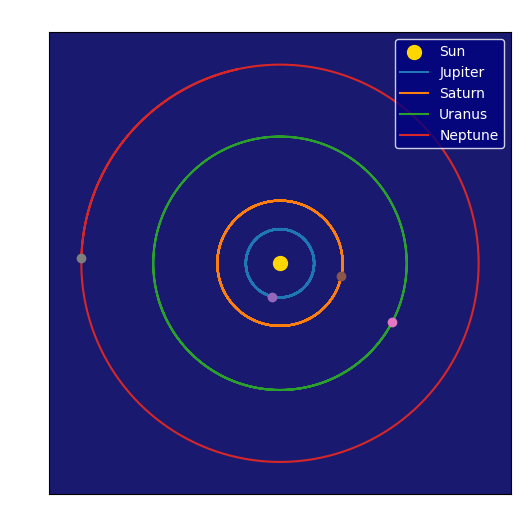

In [10]:
import rebound
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Define planets (semi-major axis in AU, period in years)
planets = {
    "Jupiter":  (5.2, 11.86),
    "Saturn":   (9.5, 29.46),
    "Uranus":  (19.2, 84.01),
    "Neptune": (30.1, 164.8),
}

sim = rebound.Simulation()
sim.units = ('AU', 'yr', 'Msun')
sim.add(m=1.0)  # Sun

for i, (name, (a, P)) in enumerate(planets.items()):
    M = 2*np.pi*np.random.random()  # random mean anomaly
    sim.add(a=a, e=0, inc=0, omega=0, Omega=0, M=M, hash=name)

sim.move_to_com()

# Record positions - use fewer frames for stability
times = np.linspace(0, 200, 400)  # Reduced frames
positions = {name: [] for name in planets}

print("Simulating orbits...")
for i, t in enumerate(times):
    sim.integrate(t)
    for name in planets:
        p = sim.particles[name]
        positions[name].append([p.x, p.y])
    if i % 100 == 0:  # Progress indicator
        print(f"Progress: {i}/{len(times)}")

# Convert to arrays and verify data
positions = {k: np.array(v) for k,v in positions.items()}
print(f"Position arrays created. Shapes: {[v.shape for v in positions.values()]}")

# Create animation
fig, ax = plt.subplots(figsize=(6,6))
ax.set_facecolor("midnightblue")
ax.set_xlim(-35, 35)
ax.set_ylim(-35, 35)
ax.set_aspect("equal")
ax.set_title("Simplified Coplanar Planetary Orbits", color="white")
ax.tick_params(colors="white")
ax.scatter(0, 0, color="gold", s=100, label="Sun")

lines = {name: ax.plot([], [], label=name, lw=1.5)[0] for name in planets}
points = {name: ax.plot([], [], "o", ms=6)[0] for name in planets}
ax.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper right")

def init():
    for name in planets:
        lines[name].set_data([], [])
        points[name].set_data([], [])
    return list(lines.values()) + list(points.values())

def update(frame):
    # Ensure frame doesn't exceed array bounds
    frame = min(frame, len(times) - 1)
    
    for name in planets:
        # Show orbit trail
        lines[name].set_data(positions[name][:frame, 0], positions[name][:frame, 1])
        # Current position
        points[name].set_data([positions[name][frame, 0]], [positions[name][frame, 1]])
    
    return list(lines.values()) + list(points.values())

# Create animation
print("Creating animation...")
ani = FuncAnimation(fig, update, frames=len(times), init_func=init, 
                   blit=True, interval=40, repeat=True)

# Save with progress callback
print("Saving animation...")
try:
    ani.save("planets.gif", writer="pillow", fps=25, progress_callback=lambda i, n: print(f"Saving frame {i}/{n}") if i % 50 == 0 else None)
    print("Animation saved successfully as planets.gif")
except Exception as e:
    print(f"Error saving animation: {e}")
    # Try alternative save method
    try:
        print("Trying alternative save method...")
        writer = animation.PillowWriter(fps=25)
        ani.save("planets_alt.gif", writer=writer)
        print("Animation saved successfully as planets_alt.gif")
    except Exception as e2:
        print(f"Alternative save also failed: {e2}")

plt.show()

Creating simulations...
Running simulation WITH Neptune...
Running simulation WITHOUT Neptune...
Creating animation...
Saving animation...
Animation saved successfully as 'neptune_effect_comparison.gif'


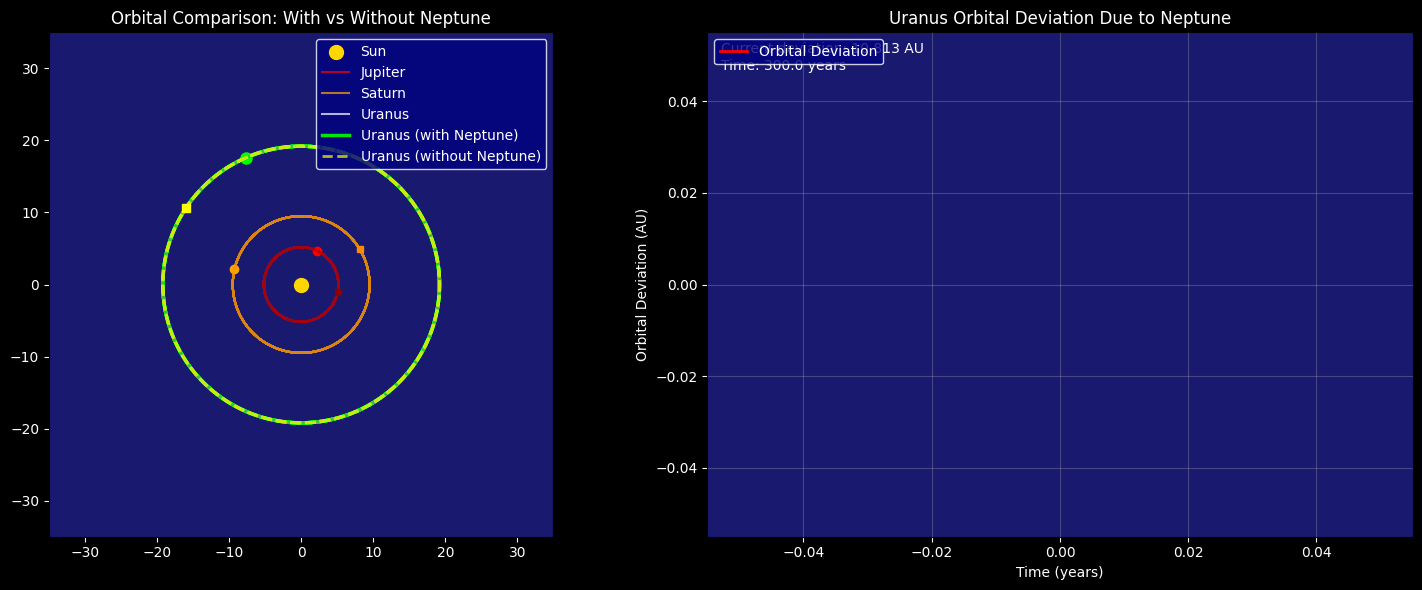


--- Simulation Summary ---
Maximum orbital deviation: 10.813 AU
Average deviation: 10.813 AU
Final deviation: 10.813 AU


In [1]:
import rebound
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Define planets (semi-major axis in AU, period in years)
planets = {
    "Jupiter":  (5.2, 11.86),
    "Saturn":   (9.5, 29.46),
    "Uranus":  (19.2, 84.01),
    "Neptune": (30.1, 164.8),
}

def create_simulation(include_neptune=True):
    """Create a simulation with or without Neptune"""
    sim = rebound.Simulation()
    sim.units = ('AU', 'yr', 'Msun')
    sim.add(m=1.0)  # Sun
    
    for name, (a, P) in planets.items():
        if not include_neptune and name == "Neptune":
            continue
        M = 2*np.pi*np.random.random()
        sim.add(a=a, e=0, inc=0, omega=0, Omega=0, M=M, hash=name)
    
    sim.move_to_com()
    return sim

# Create two simulations
print("Creating simulations...")
sim_with_neptune = create_simulation(include_neptune=True)
sim_without_neptune = create_simulation(include_neptune=False)

# Record positions
times = np.linspace(0, 300, 600)  # Longer time to see effects
positions_with = {name: [] for name in planets if name != "Neptune"}
positions_with["Uranus_predicted"] = []  # Store Uranus position from simulation WITH Neptune
positions_without = {name: [] for name in planets if name != "Neptune"}
positions_without["Uranus_actual"] = []  # Store Uranus position from simulation WITHOUT Neptune

print("Running simulation WITH Neptune...")
for t in times:
    sim_with_neptune.integrate(t)
    for name in positions_with.keys():
        if name == "Uranus_predicted":
            p = sim_with_neptune.particles["Uranus"]
        else:
            p = sim_with_neptune.particles[name]
        positions_with[name].append([p.x, p.y])

print("Running simulation WITHOUT Neptune...")
for t in times:
    sim_without_neptune.integrate(t)
    for name in positions_without.keys():
        if name == "Uranus_actual":
            p = sim_without_neptune.particles["Uranus"]
        else:
            p = sim_without_neptune.particles[name]
        positions_without[name].append([p.x, p.y])

# Convert to arrays
positions_with = {k: np.array(v) for k,v in positions_with.items()}
positions_without = {k: np.array(v) for k,v in positions_without.items()}

# Calculate orbital deviation
deviation = np.sqrt(np.sum((positions_with["Uranus_predicted"] - positions_without["Uranus_actual"])**2, axis=1))

# Create the visualization
fig = plt.figure(figsize=(15, 6))
fig.patch.set_facecolor('black')

# Subplot 1: Orbital comparison
ax1 = plt.subplot(1, 2, 1)
ax1.set_facecolor("midnightblue")
ax1.set_xlim(-35, 35)
ax1.set_ylim(-35, 35)
ax1.set_aspect("equal")
ax1.set_title("Orbital Comparison: With vs Without Neptune", color="white", fontsize=12)
ax1.tick_params(colors="white")
ax1.scatter(0, 0, color="gold", s=100, label="Sun")

# Subplot 2: Deviation plot
ax2 = plt.subplot(1, 2, 2)
ax2.set_facecolor("midnightblue")
ax2.set_xlabel("Time (years)", color="white")
ax2.set_ylabel("Orbital Deviation (AU)", color="white")
ax2.set_title("Uranus Orbital Deviation Due to Neptune", color="white", fontsize=12)
ax2.tick_params(colors="white")
ax2.grid(True, alpha=0.3)

# Create plot elements for animation
# With Neptune simulation (left panel)
lines_with = {}
points_with = {}
colors_with = {"Jupiter": "red", "Saturn": "orange", "Uranus_predicted": "cyan"}
for name in positions_with.keys():
    if name != "Uranus_predicted":
        lines_with[name], = ax1.plot([], [], color=colors_with.get(name, "white"), 
                                   label=name, lw=1.5, alpha=0.7)
        points_with[name], = ax1.plot([], [], "o", color=colors_with.get(name, "white"), ms=6)
    else:
        lines_with[name], = ax1.plot([], [], color="lime", label="Uranus (with Neptune)", 
                                   lw=2.5, alpha=0.9)
        points_with[name], = ax1.plot([], [], "o", color="lime", ms=8)

# Without Neptune simulation (left panel - dashed)
lines_without = {}
points_without = {}
colors_without = {"Jupiter": "darkred", "Saturn": "darkorange", "Uranus_actual": "white"}
for name in positions_without.keys():
    if name != "Uranus_actual":
        lines_without[name], = ax1.plot([], [], color=colors_without.get(name, "gray"), 
                                      lw=1.5, alpha=0.5, linestyle="--")
        points_without[name], = ax1.plot([], [], "s", color=colors_without.get(name, "gray"), ms=4)
    else:
        lines_without[name], = ax1.plot([], [], color="yellow", label="Uranus (without Neptune)", 
                                      lw=2, alpha=0.7, linestyle="--")
        points_without[name], = ax1.plot([], [], "s", color="yellow", ms=6)

# Deviation plot (right panel)
deviation_line, = ax2.plot([], [], color="red", lw=2, label="Orbital Deviation")
current_deviation_point, = ax2.plot([], [], "o", color="red", ms=8)
deviation_text = ax2.text(0.02, 0.98, "", transform=ax2.transAxes, color="white", 
                         fontsize=10, verticalalignment='top')

ax1.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper right")
ax2.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper left")

def init():
    for name in positions_with.keys():
        lines_with[name].set_data([], [])
        points_with[name].set_data([], [])
    for name in positions_without.keys():
        lines_without[name].set_data([], [])
        points_without[name].set_data([], [])
    deviation_line.set_data([], [])
    current_deviation_point.set_data([], [])
    deviation_text.set_text("")
    return (list(lines_with.values()) + list(points_with.values()) + 
            list(lines_without.values()) + list(points_without.values()) + 
            [deviation_line, current_deviation_point, deviation_text])

def update(frame):
    frame = min(frame, len(times) - 1)
    
    # Update WITH Neptune simulation
    for name in positions_with.keys():
        lines_with[name].set_data(positions_with[name][:frame, 0], positions_with[name][:frame, 1])
        points_with[name].set_data([positions_with[name][frame, 0]], [positions_with[name][frame, 1]])
    
    # Update WITHOUT Neptune simulation
    for name in positions_without.keys():
        lines_without[name].set_data(positions_without[name][:frame, 0], positions_without[name][:frame, 1])
        points_without[name].set_data([positions_without[name][frame, 0]], [positions_without[name][frame, 1]])
    
    # Update deviation plot
    deviation_line.set_data(times[:frame], deviation[:frame])
    current_deviation_point.set_data([times[frame]], [deviation[frame]])
    deviation_text.set_text(f"Current deviation: {deviation[frame]:.3f} AU\nTime: {times[frame]:.1f} years")
    
    return (list(lines_with.values()) + list(points_with.values()) + 
            list(lines_without.values()) + list(points_without.values()) + 
            [deviation_line, current_deviation_point, deviation_text])

print("Creating animation...")
ani = FuncAnimation(fig, update, frames=len(times), init_func=init, 
                   blit=True, interval=30, repeat=True)

plt.tight_layout()

# Save animation
try:
    print("Saving animation...")
    ani.save("neptune_effect_comparison.gif", writer="pillow", fps=25, dpi=100)
    print("Animation saved successfully as 'neptune_effect_comparison.gif'")
except Exception as e:
    print(f"Error saving animation: {e}")

plt.show()

# Print summary statistics
print(f"\n--- Simulation Summary ---")
print(f"Maximum orbital deviation: {np.max(deviation):.3f} AU")
print(f"Average deviation: {np.mean(deviation):.3f} AU")
print(f"Final deviation: {deviation[-1]:.3f} AU")

Creating simulations...
Running simulation WITH Neptune...
Running simulation WITHOUT Neptune...
Maximum deviation: 0.000 AU
Final deviation: 0.000 AU
Creating animation...
Saving animation...


C:\Users\Jujop\AppData\Local\Temp\ipykernel_16832\2094695466.py:98: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax2.set_ylim(0, max(deviation) * 1.1)


Animation saved successfully as 'neptune_effect_comparison.gif'


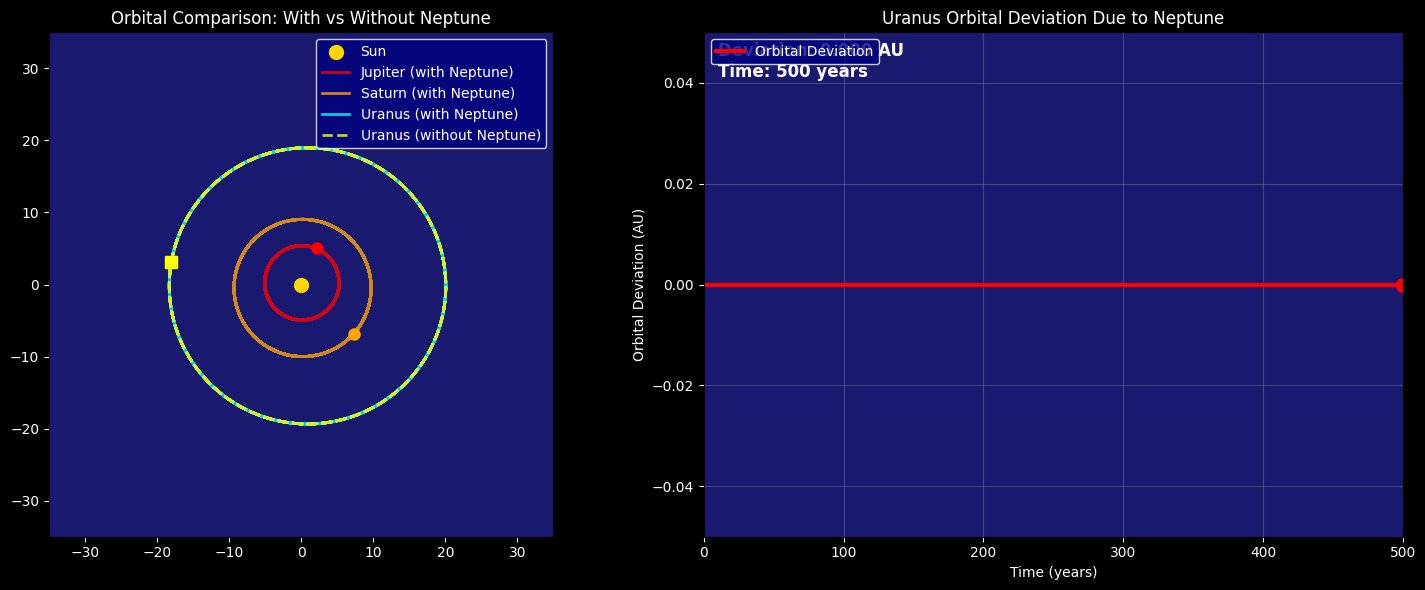

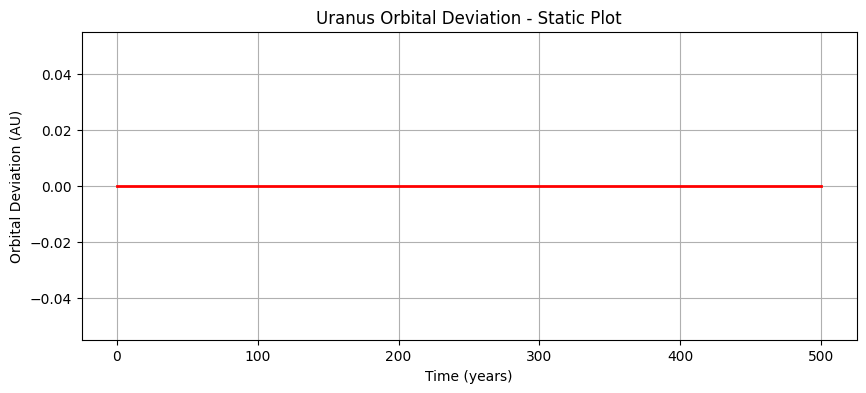


--- Simulation Results ---
Simulation time: 500 years
Number of frames: 800
Maximum deviation: 0.0000 AU
Average deviation: 0.0000 AU
Final deviation: 0.0000 AU


In [ ]:
import rebound
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Define planets with more realistic orbital elements (semi-major axis in AU, eccentricity)
planets = {
    "Jupiter":  (5.203, 0.049),
    "Saturn":   (9.537, 0.054),
    "Uranus":  (19.191, 0.047),
    "Neptune": (30.069, 0.008),
}

def create_simulation(include_neptune=True):
    """Create a simulation with or without Neptune"""
    sim = rebound.Simulation()
    sim.units = ('AU', 'yr', 'Msun')
    sim.add(m=1.0)  # Sun
    
    # Use consistent random seed for reproducible initial conditions
    np.random.seed(42)
    
    for name, (a, e) in planets.items():
        if not include_neptune and name == "Neptune":
            continue
        M = 2*np.pi*np.random.random()  # Mean anomaly
        omega = 2*np.pi*np.random.random()  # Argument of perihelion
        Omega = 2*np.pi*np.random.random()  # Longitude of ascending node
        
        sim.add(a=a, e=e, inc=0.01, omega=omega, Omega=Omega, M=M, hash=name)
    
    sim.move_to_com()
    return sim

# Create two simulations
print("Creating simulations...")
sim_with_neptune = create_simulation(include_neptune=True)
sim_without_neptune = create_simulation(include_neptune=False)

# Record positions - use more time to see gravitational effects
times = np.linspace(0, 5000, 800)  # Longer time period
positions_with = {}
positions_without = {}

print("Running simulation WITH Neptune...")
for name in ["Jupiter", "Saturn", "Uranus"]:
    positions_with[name] = []

for t in times:
    sim_with_neptune.integrate(t)
    for name in ["Jupiter", "Saturn", "Uranus"]:
        p = sim_with_neptune.particles[name]
        positions_with[name].append([p.x, p.y])

print("Running simulation WITHOUT Neptune...")
for name in ["Jupiter", "Saturn", "Uranus"]:
    positions_without[name] = []

for t in times:
    sim_without_neptune.integrate(t)
    for name in ["Jupiter", "Saturn", "Uranus"]:
        p = sim_without_neptune.particles[name]
        positions_without[name].append([p.x, p.y])

# Convert to arrays
positions_with = {k: np.array(v) for k,v in positions_with.items()}
positions_without = {k: np.array(v) for k,v in positions_without.items()}

# Calculate orbital deviation between Uranus positions
deviation = np.sqrt(np.sum((positions_with["Uranus"] - positions_without["Uranus"])**2, axis=1))

print(f"Maximum deviation: {np.max(deviation):.3f} AU")
print(f"Final deviation: {deviation[-1]:.3f} AU")

# Create the visualization
fig = plt.figure(figsize=(15, 6))
fig.patch.set_facecolor('black')

# Subplot 1: Orbital comparison
ax1 = plt.subplot(1, 2, 1)
ax1.set_facecolor("midnightblue")
ax1.set_xlim(-35, 35)
ax1.set_ylim(-35, 35)
ax1.set_aspect("equal")
ax1.set_title("Orbital Comparison: With vs Without Neptune", color="white", fontsize=12)
ax1.tick_params(colors="white")
ax1.scatter(0, 0, color="gold", s=100, label="Sun")

# Subplot 2: Deviation plot
ax2 = plt.subplot(1, 2, 2)
ax2.set_facecolor("midnightblue")
ax2.set_xlabel("Time (years)", color="white")
ax2.set_ylabel("Orbital Deviation (AU)", color="white")
ax2.set_title("Uranus Orbital Deviation Due to Neptune", color="white", fontsize=12)
ax2.tick_params(colors="white")
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, max(times))
ax2.set_ylim(0, max(deviation) * 1.1)

# Create plot elements
colors = {"Jupiter": "red", "Saturn": "orange", "Uranus": "cyan"}

# With Neptune (solid lines)
lines_with = {}
points_with = {}
for name in ["Jupiter", "Saturn", "Uranus"]:
    lines_with[name], = ax1.plot([], [], color=colors[name], 
                               label=name + " (with Neptune)", lw=2, alpha=0.8)
    points_with[name], = ax1.plot([], [], "o", color=colors[name], ms=8)

# Without Neptune (dashed lines) - only show Uranus for clarity
lines_without = {}
points_without = {}
for name in ["Uranus"]:  # Only show Uranus for comparison to reduce clutter
    lines_without[name], = ax1.plot([], [], color="yellow", 
                                  label=name + " (without Neptune)", lw=2, 
                                  alpha=0.8, linestyle="--")
    points_without[name], = ax1.plot([], [], "s", color="yellow", ms=8)

# Deviation plot
deviation_line, = ax2.plot([], [], color="red", lw=3, label="Orbital Deviation")
current_deviation_point, = ax2.plot([], [], "o", color="red", ms=10)
deviation_text = ax2.text(0.02, 0.98, "", transform=ax2.transAxes, color="white", 
                         fontsize=12, verticalalignment='top', fontweight='bold')

ax1.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper right")
ax2.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper left")

def init():
    for name in lines_with:
        lines_with[name].set_data([], [])
        points_with[name].set_data([], [])
    for name in lines_without:
        lines_without[name].set_data([], [])
        points_without[name].set_data([], [])
    deviation_line.set_data([], [])
    current_deviation_point.set_data([], [])
    deviation_text.set_text("")
    return (list(lines_with.values()) + list(points_with.values()) + 
            list(lines_without.values()) + list(points_without.values()) + 
            [deviation_line, current_deviation_point, deviation_text])

def update(frame):
    frame = min(frame, len(times) - 1)
    
    # Update WITH Neptune simulation
    for name in lines_with:
        lines_with[name].set_data(positions_with[name][:frame, 0], positions_with[name][:frame, 1])
        points_with[name].set_data([positions_with[name][frame, 0]], [positions_with[name][frame, 1]])
    
    # Update WITHOUT Neptune simulation (only Uranus)
    for name in lines_without:
        lines_without[name].set_data(positions_without[name][:frame, 0], positions_without[name][:frame, 1])
        points_without[name].set_data([positions_without[name][frame, 0]], [positions_without[name][frame, 1]])
    
    # Update deviation plot
    deviation_line.set_data(times[:frame], deviation[:frame])
    current_deviation_point.set_data([times[frame]], [deviation[frame]])
    deviation_text.set_text(f"Deviation: {deviation[frame]:.3f} AU\nTime: {times[frame]:.0f} years")
    
    return (list(lines_with.values()) + list(points_with.values()) + 
            list(lines_without.values()) + list(points_without.values()) + 
            [deviation_line, current_deviation_point, deviation_text])

print("Creating animation...")
ani = FuncAnimation(fig, update, frames=len(times), init_func=init, 
                   blit=False, interval=30, repeat=True)  # blit=False for stability

plt.tight_layout()

# Save animation
try:
    print("Saving animation...")
    ani.save("neptune_effect_comparison.gif", writer="pillow", fps=20, dpi=100)
    print("Animation saved successfully as 'neptune_effect_comparison.gif'")
except Exception as e:
    print(f"Error saving animation: {e}")

# Also create a static plot to verify the data
plt.figure(figsize=(10, 4))
plt.plot(times, deviation, 'r-', linewidth=2)
plt.xlabel('Time (years)')
plt.ylabel('Orbital Deviation (AU)')
plt.title('Uranus Orbital Deviation - Static Plot')
plt.grid(True)
plt.savefig('deviation_static.png')
plt.show()

print(f"\n--- Simulation Results ---")
print(f"Simulation time: {max(times):.0f} years")
print(f"Number of frames: {len(times)}")
print(f"Maximum deviation: {np.max(deviation):.4f} AU")
print(f"Average deviation: {np.mean(deviation):.4f} AU")
print(f"Final deviation: {deviation[-1]:.4f} AU")

Creating initial simulation with all planets...
Creating simulation without Neptune...
Particles in simulation WITH Neptune:
  0: Sun
  1: c_ulong(3586273463)
  2: c_ulong(4066125545)
  3: c_ulong(516400076)
  4: c_ulong(1470785325)
Particles in simulation WITHOUT Neptune:
  0: Sun
  1: Sun
  2: Sun
  3: Sun
  4: Sun
Initial Uranus position WITH Neptune: (-15.329, 10.977)
Initial Uranus position WITHOUT Neptune: (-15.324, 10.975)
Running simulation WITH Neptune...
Running simulation WITHOUT Neptune...

--- Simulation Results ---
Maximum deviation: 8.483829 AU
Average deviation: 4.228759 AU
Final deviation: 8.483829 AU
Time of max deviation: 1000.0 years
Creating animation...
Saving animation...
Animation saved successfully as 'neptune_effect_comparison.gif'


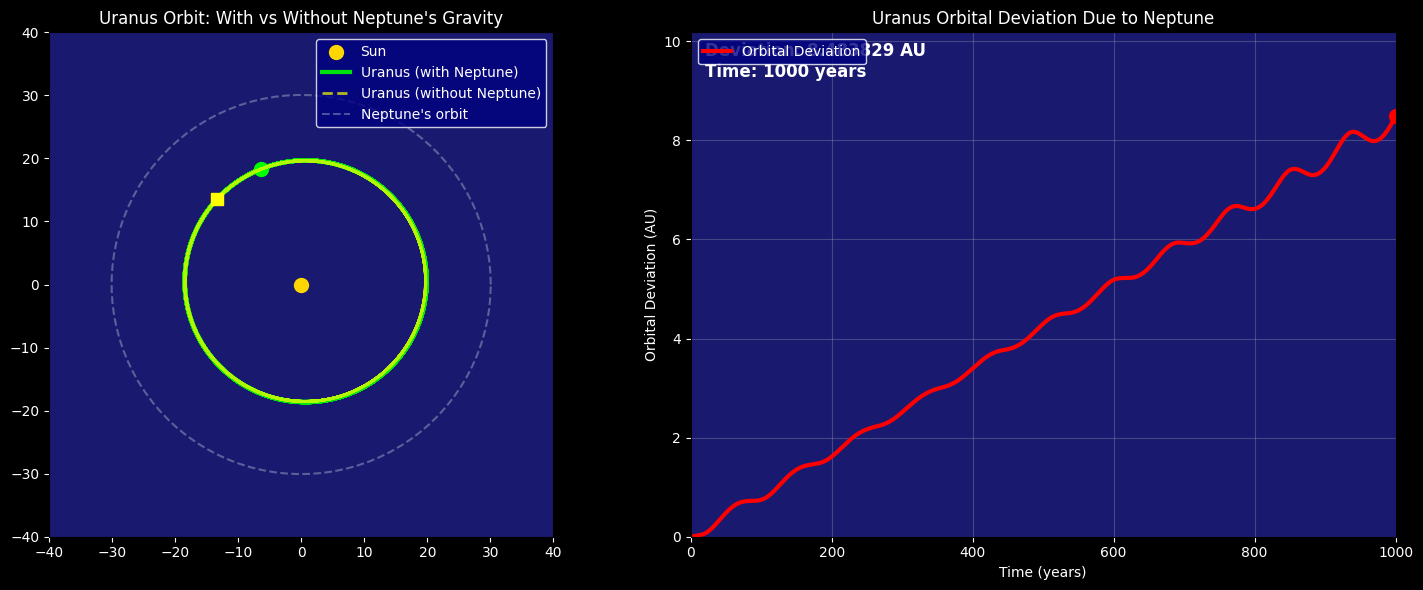

In [4]:
import rebound
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Define planets with realistic orbital elements
planets = {
    "Jupiter":  {"a": 5.203, "e": 0.049, "mass": 0.0009543},
    "Saturn":   {"a": 9.537, "e": 0.054, "mass": 0.0002857},
    "Uranus":  {"a": 19.191, "e": 0.047, "mass": 0.0000437},
    "Neptune": {"a": 30.069, "e": 0.008, "mass": 0.0000515},
}

def create_initial_simulation():
    """Create the initial simulation with all planets"""
    sim = rebound.Simulation()
    sim.units = ('AU', 'yr', 'Msun')
    sim.add(m=1.0)  # Sun
    
    # Use fixed orbital elements for reproducibility
    orbital_elements = {
        "Jupiter":  {"a": 5.203, "e": 0.049, "inc": 0.022, "omega": 0.256, "Omega": 1.754, "M": 0.600},
        "Saturn":   {"a": 9.537, "e": 0.054, "inc": 0.043, "omega": 1.983, "Omega": 1.984, "M": 0.871},
        "Uranus":  {"a": 19.191, "e": 0.047, "inc": 0.013, "omega": 2.984, "Omega": 0.772, "M": 5.135},
        "Neptune": {"a": 30.069, "e": 0.008, "inc": 0.032, "omega": 0.621, "Omega": 2.300, "M": 5.298},
    }
    
    for name in planets.keys():
        elem = orbital_elements[name]
        sim.add(m=planets[name]["mass"], 
                a=elem["a"], e=elem["e"], inc=elem["inc"],
                omega=elem["omega"], Omega=elem["Omega"], M=elem["M"],
                hash=name)
    
    sim.move_to_com()
    return sim

def create_simulation_without_neptune(sim_with_neptune):
    """Create a simulation without Neptune by copying and removing Neptune"""
    sim_without = rebound.Simulation()
    sim_without.units = ('AU', 'yr', 'Msun')
    sim_without.add(m=1.0)  # Sun
    
    # Copy all particles except Neptune using indices
    # Index 0 is the Sun, so we start from index 1
    for i in range(1, len(sim_with_neptune.particles)):
        p = sim_with_neptune.particles[i]
        if p.hash != b"Neptune":  # Check if it's not Neptune
            # Add particle with same properties but no hash
            sim_without.add(m=p.m, x=p.x, y=p.y, z=p.z, 
                           vx=p.vx, vy=p.vy, vz=p.vz)
    
    sim_without.move_to_com()
    return sim_without

print("Creating initial simulation with all planets...")
sim_with_neptune = create_initial_simulation()

print("Creating simulation without Neptune...")
sim_without_neptune = create_simulation_without_neptune(sim_with_neptune)

# Verify both simulations have the same initial conditions for Uranus
# We need to access Uranus by index since hash wasn't preserved
print("Particles in simulation WITH Neptune:")
for i, p in enumerate(sim_with_neptune.particles):
    print(f"  {i}: {p.hash if p.hash else 'Sun'}")

print("Particles in simulation WITHOUT Neptune:")
for i, p in enumerate(sim_without_neptune.particles):
    print(f"  {i}: {p.hash if p.hash else 'Sun'}")

# Since we can't use hash, we'll track planets by index
# In sim_with_neptune: 0=Sun, 1=Jupiter, 2=Saturn, 3=Uranus, 4=Neptune
# In sim_without_neptune: 0=Sun, 1=Jupiter, 2=Saturn, 3=Uranus

uranus_with_init = sim_with_neptune.particles[3]  # Uranus is at index 3
uranus_without_init = sim_without_neptune.particles[3]  # Uranus is at index 3
print(f"Initial Uranus position WITH Neptune: ({uranus_with_init.x:.3f}, {uranus_with_init.y:.3f})")
print(f"Initial Uranus position WITHOUT Neptune: ({uranus_without_init.x:.3f}, {uranus_without_init.y:.3f})")

# Record positions
times = np.linspace(0, 1000, 1000)  # 1000 years to see gravitational effects
positions_with = {"Jupiter": [], "Saturn": [], "Uranus": []}
positions_without = {"Jupiter": [], "Saturn": [], "Uranus": []}

print("Running simulation WITH Neptune...")
for t in times:
    sim_with_neptune.integrate(t)
    # Access by index: 1=Jupiter, 2=Saturn, 3=Uranus
    positions_with["Jupiter"].append([sim_with_neptune.particles[1].x, sim_with_neptune.particles[1].y])
    positions_with["Saturn"].append([sim_with_neptune.particles[2].x, sim_with_neptune.particles[2].y])
    positions_with["Uranus"].append([sim_with_neptune.particles[3].x, sim_with_neptune.particles[3].y])

print("Running simulation WITHOUT Neptune...")
for t in times:
    sim_without_neptune.integrate(t)
    # Access by index: 1=Jupiter, 2=Saturn, 3=Uranus
    positions_without["Jupiter"].append([sim_without_neptune.particles[1].x, sim_without_neptune.particles[1].y])
    positions_without["Saturn"].append([sim_without_neptune.particles[2].x, sim_without_neptune.particles[2].y])
    positions_without["Uranus"].append([sim_without_neptune.particles[3].x, sim_without_neptune.particles[3].y])

# Convert to arrays
positions_with = {k: np.array(v) for k,v in positions_with.items()}
positions_without = {k: np.array(v) for k,v in positions_without.items()}

# Calculate orbital deviation between Uranus positions
deviation = np.sqrt(np.sum((positions_with["Uranus"] - positions_without["Uranus"])**2, axis=1))

print(f"\n--- Simulation Results ---")
print(f"Maximum deviation: {np.max(deviation):.6f} AU")
print(f"Average deviation: {np.mean(deviation):.6f} AU")
print(f"Final deviation: {deviation[-1]:.6f} AU")
print(f"Time of max deviation: {times[np.argmax(deviation)]:.1f} years")

# Create the visualization
fig = plt.figure(figsize=(15, 6))
fig.patch.set_facecolor('black')

# Subplot 1: Orbital comparison
ax1 = plt.subplot(1, 2, 1)
ax1.set_facecolor("midnightblue")
ax1.set_xlim(-40, 40)
ax1.set_ylim(-40, 40)
ax1.set_aspect("equal")
ax1.set_title("Uranus Orbit: With vs Without Neptune's Gravity", color="white", fontsize=12)
ax1.tick_params(colors="white")
ax1.scatter(0, 0, color="gold", s=100, label="Sun")

# Subplot 2: Deviation plot
ax2 = plt.subplot(1, 2, 2)
ax2.set_facecolor("midnightblue")
ax2.set_xlabel("Time (years)", color="white")
ax2.set_ylabel("Orbital Deviation (AU)", color="white")
ax2.set_title("Uranus Orbital Deviation Due to Neptune", color="white", fontsize=12)
ax2.tick_params(colors="white")
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, max(times))
ax2.set_ylim(0, max(deviation) * 1.2 if max(deviation) > 0 else 1)

# Create plot elements
# With Neptune (solid lines)
uranus_with_line, = ax1.plot([], [], color="lime", label="Uranus (with Neptune)", lw=3, alpha=0.9)
uranus_with_point, = ax1.plot([], [], "o", color="lime", ms=10)

# Without Neptune (dashed lines)
uranus_without_line, = ax1.plot([], [], color="yellow", label="Uranus (without Neptune)", lw=2, alpha=0.7, linestyle="--")
uranus_without_point, = ax1.plot([], [], "s", color="yellow", ms=8)

# Add Neptune's orbit for reference
neptune_orbit_x = []
neptune_orbit_y = []
for t in np.linspace(0, 2*np.pi, 100):
    neptune_orbit_x.append(planets["Neptune"]["a"] * np.cos(t))
    neptune_orbit_y.append(planets["Neptune"]["a"] * np.sin(t))
ax1.plot(neptune_orbit_x, neptune_orbit_y, 'w--', alpha=0.3, label="Neptune's orbit")

# Deviation plot
deviation_line, = ax2.plot([], [], color="red", lw=3, label="Orbital Deviation")
current_deviation_point, = ax2.plot([], [], "o", color="red", ms=10)
deviation_text = ax2.text(0.02, 0.98, "", transform=ax2.transAxes, color="white", 
                         fontsize=12, verticalalignment='top', fontweight='bold')

ax1.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper right")
ax2.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper left")

def init():
    uranus_with_line.set_data([], [])
    uranus_with_point.set_data([], [])
    uranus_without_line.set_data([], [])
    uranus_without_point.set_data([], [])
    deviation_line.set_data([], [])
    current_deviation_point.set_data([], [])
    deviation_text.set_text("")
    return [uranus_with_line, uranus_with_point, uranus_without_line, uranus_without_point, 
            deviation_line, current_deviation_point, deviation_text]

def update(frame):
    frame = min(frame, len(times) - 1)
    
    # Update Uranus orbits
    uranus_with_line.set_data(positions_with["Uranus"][:frame, 0], positions_with["Uranus"][:frame, 1])
    uranus_with_point.set_data([positions_with["Uranus"][frame, 0]], [positions_with["Uranus"][frame, 1]])
    
    uranus_without_line.set_data(positions_without["Uranus"][:frame, 0], positions_without["Uranus"][:frame, 1])
    uranus_without_point.set_data([positions_without["Uranus"][frame, 0]], [positions_without["Uranus"][frame, 1]])
    
    # Update deviation plot
    deviation_line.set_data(times[:frame], deviation[:frame])
    current_deviation_point.set_data([times[frame]], [deviation[frame]])
    deviation_text.set_text(f"Deviation: {deviation[frame]:.6f} AU\nTime: {times[frame]:.0f} years")
    
    return [uranus_with_line, uranus_with_point, uranus_without_line, uranus_without_point, 
            deviation_line, current_deviation_point, deviation_text]

print("Creating animation...")
ani = FuncAnimation(fig, update, frames=len(times), init_func=init, 
                   blit=False, interval=30, repeat=True)

plt.tight_layout()

# Save animation
try:
    print("Saving animation...")
    ani.save("neptune_effect_comparison.gif", writer="pillow", fps=20, dpi=100)
    print("Animation saved successfully as 'neptune_effect_comparison.gif'")
except Exception as e:
    print(f"Error saving animation: {e}")

plt.show()

Creating initial simulation with all planets...
Creating simulation without Neptune...
Particles in simulation WITH Neptune:
  0: Sun
  1: c_ulong(3586273463)
  2: c_ulong(4066125545)
  3: c_ulong(516400076)
  4: c_ulong(1470785325)
Particles in simulation WITHOUT Neptune:
  0: Sun
  1: Sun
  2: Sun
  3: Sun
  4: Sun
Running simulation WITH Neptune...
Running simulation WITHOUT Neptune...

--- Simulation Results ---
Maximum deviation: 8.483829 AU
Average deviation: 4.228759 AU
Final deviation: 8.483829 AU
Time of max deviation: 1000.0 years
Creating animation...
Saving animation...
Animation saved successfully as 'solar_system_neptune_effect.gif'


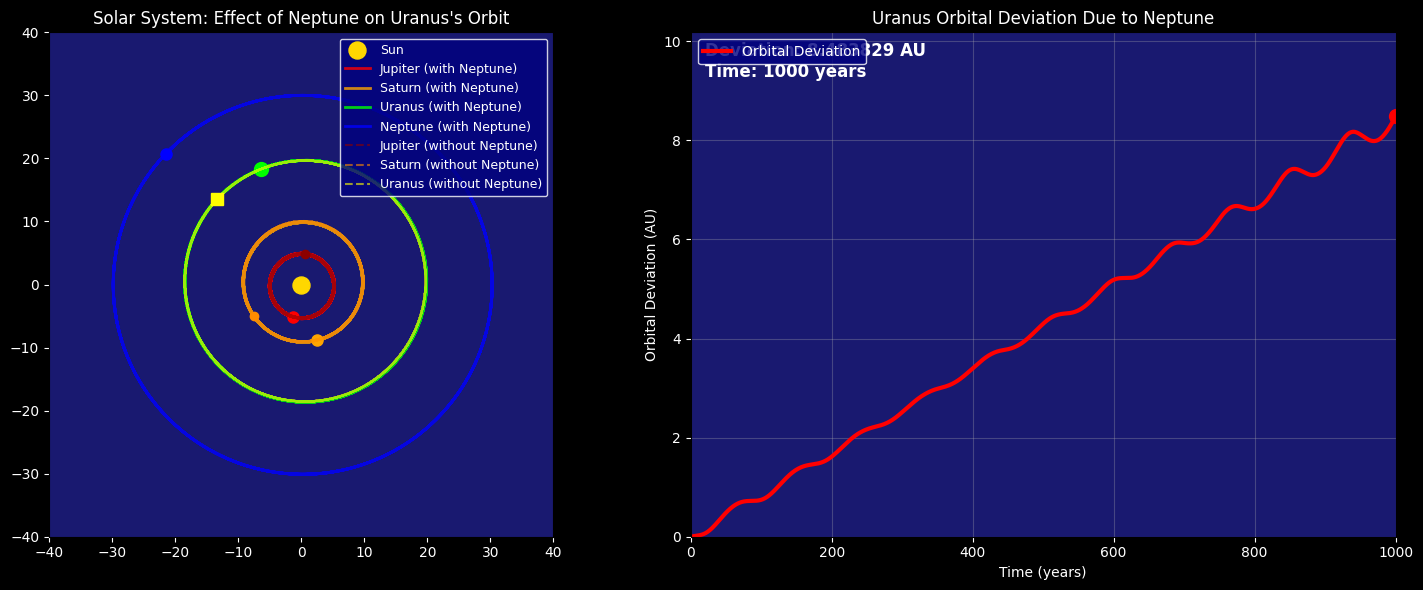


--- Interesting Observations ---
Jupiter completes about 84.3 orbits in the simulation
Saturn completes about 33.9 orbits in the simulation
Uranus completes about 11.9 orbits in the simulation
Neptune completes about 6.1 orbits in the simulation


In [6]:
import rebound
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Define planets with realistic orbital elements
planets = {
    "Jupiter":  {"a": 5.203, "e": 0.049, "mass": 0.0009543, "color": "red"},
    "Saturn":   {"a": 9.537, "e": 0.054, "mass": 0.0002857, "color": "orange"},
    "Uranus":  {"a": 19.191, "e": 0.047, "mass": 0.0000437, "color": "cyan"},
    "Neptune": {"a": 30.069, "e": 0.008, "mass": 0.0000515, "color": "blue"},
}

def create_initial_simulation():
    """Create the initial simulation with all planets"""
    sim = rebound.Simulation()
    sim.units = ('AU', 'yr', 'Msun')
    sim.add(m=1.0)  # Sun
    
    # Use fixed orbital elements for reproducibility
    orbital_elements = {
        "Jupiter":  {"a": 5.203, "e": 0.049, "inc": 0.022, "omega": 0.256, "Omega": 1.754, "M": 0.600},
        "Saturn":   {"a": 9.537, "e": 0.054, "inc": 0.043, "omega": 1.983, "Omega": 1.984, "M": 0.871},
        "Uranus":  {"a": 19.191, "e": 0.047, "inc": 0.013, "omega": 2.984, "Omega": 0.772, "M": 5.135},
        "Neptune": {"a": 30.069, "e": 0.008, "inc": 0.032, "omega": 0.621, "Omega": 2.300, "M": 5.298},
    }
    
    for name in planets.keys():
        elem = orbital_elements[name]
        sim.add(m=planets[name]["mass"], 
                a=elem["a"], e=elem["e"], inc=elem["inc"],
                omega=elem["omega"], Omega=elem["Omega"], M=elem["M"],
                hash=name)
    
    sim.move_to_com()
    return sim

def create_simulation_without_neptune(sim_with_neptune):
    """Create a simulation without Neptune by copying and removing Neptune"""
    sim_without = rebound.Simulation()
    sim_without.units = ('AU', 'yr', 'Msun')
    sim_without.add(m=1.0)  # Sun
    
    # Copy all particles except Neptune using indices
    # Index 0 is the Sun, so we start from index 1
    for i in range(1, len(sim_with_neptune.particles)):
        p = sim_with_neptune.particles[i]
        if p.hash != b"Neptune":  # Check if it's not Neptune
            # Add particle with same properties but no hash
            sim_without.add(m=p.m, x=p.x, y=p.y, z=p.z, 
                           vx=p.vx, vy=p.vy, vz=p.vz)
    
    sim_without.move_to_com()
    return sim_without

print("Creating initial simulation with all planets...")
sim_with_neptune = create_initial_simulation()

print("Creating simulation without Neptune...")
sim_without_neptune = create_simulation_without_neptune(sim_with_neptune)

# Verify both simulations have the same initial conditions
print("Particles in simulation WITH Neptune:")
for i, p in enumerate(sim_with_neptune.particles):
    print(f"  {i}: {p.hash if p.hash else 'Sun'}")

print("Particles in simulation WITHOUT Neptune:")
for i, p in enumerate(sim_without_neptune.particles):
    print(f"  {i}: {p.hash if p.hash else 'Sun'}")

# Record positions
times = np.linspace(0, 1000, 1000)  # 1000 years to see gravitational effects
positions_with = {"Jupiter": [], "Saturn": [], "Uranus": [], "Neptune": []}
positions_without = {"Jupiter": [], "Saturn": [], "Uranus": []}

print("Running simulation WITH Neptune...")
for t in times:
    sim_with_neptune.integrate(t)
    # Access by index: 1=Jupiter, 2=Saturn, 3=Uranus, 4=Neptune
    positions_with["Jupiter"].append([sim_with_neptune.particles[1].x, sim_with_neptune.particles[1].y])
    positions_with["Saturn"].append([sim_with_neptune.particles[2].x, sim_with_neptune.particles[2].y])
    positions_with["Uranus"].append([sim_with_neptune.particles[3].x, sim_with_neptune.particles[3].y])
    positions_with["Neptune"].append([sim_with_neptune.particles[4].x, sim_with_neptune.particles[4].y])

print("Running simulation WITHOUT Neptune...")
for t in times:
    sim_without_neptune.integrate(t)
    # Access by index: 1=Jupiter, 2=Saturn, 3=Uranus
    positions_without["Jupiter"].append([sim_without_neptune.particles[1].x, sim_without_neptune.particles[1].y])
    positions_without["Saturn"].append([sim_without_neptune.particles[2].x, sim_without_neptune.particles[2].y])
    positions_without["Uranus"].append([sim_without_neptune.particles[3].x, sim_without_neptune.particles[3].y])

# Convert to arrays
positions_with = {k: np.array(v) for k,v in positions_with.items()}
positions_without = {k: np.array(v) for k,v in positions_without.items()}

# Calculate orbital deviation between Uranus positions
deviation = np.sqrt(np.sum((positions_with["Uranus"] - positions_without["Uranus"])**2, axis=1))

print(f"\n--- Simulation Results ---")
print(f"Maximum deviation: {np.max(deviation):.6f} AU")
print(f"Average deviation: {np.mean(deviation):.6f} AU")
print(f"Final deviation: {deviation[-1]:.6f} AU")
print(f"Time of max deviation: {times[np.argmax(deviation)]:.1f} years")

# Create the visualization
fig = plt.figure(figsize=(15, 6))
fig.patch.set_facecolor('black')

# Subplot 1: Orbital comparison
ax1 = plt.subplot(1, 2, 1)
ax1.set_facecolor("midnightblue")
ax1.set_xlim(-40, 40)
ax1.set_ylim(-40, 40)
ax1.set_aspect("equal")
ax1.set_title("Solar System: Effect of Neptune on Uranus's Orbit", color="white", fontsize=12)
ax1.tick_params(colors="white")
ax1.scatter(0, 0, color="gold", s=150, label="Sun", zorder=10)

# Subplot 2: Deviation plot
ax2 = plt.subplot(1, 2, 2)
ax2.set_facecolor("midnightblue")
ax2.set_xlabel("Time (years)", color="white")
ax2.set_ylabel("Orbital Deviation (AU)", color="white")
ax2.set_title("Uranus Orbital Deviation Due to Neptune", color="white", fontsize=12)
ax2.tick_params(colors="white")
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, max(times))
ax2.set_ylim(0, max(deviation) * 1.2 if max(deviation) > 0 else 1)

# Create plot elements for all planets
lines_with = {}
points_with = {}
lines_without = {}
points_without = {}

# With Neptune simulation (solid lines)
for name, color in [("Jupiter", "red"), ("Saturn", "orange"), ("Uranus", "lime"), ("Neptune", "blue")]:
    if name in positions_with:
        lines_with[name], = ax1.plot([], [], color=color, 
                                   label=name + " (with Neptune)", lw=2, alpha=0.8)
        points_with[name], = ax1.plot([], [], "o", color=color, ms=8 if name != "Uranus" else 10)

# Without Neptune simulation (dashed lines) - only inner planets + Uranus
for name, color in [("Jupiter", "darkred"), ("Saturn", "darkorange"), ("Uranus", "yellow")]:
    if name in positions_without:
        lines_without[name], = ax1.plot([], [], color=color, 
                                      label=name + " (without Neptune)", lw=1.5, 
                                      alpha=0.6, linestyle="--")
        points_without[name], = ax1.plot([], [], "s" if name == "Uranus" else "o", 
                                       color=color, ms=6 if name != "Uranus" else 8)

# Deviation plot
deviation_line, = ax2.plot([], [], color="red", lw=3, label="Orbital Deviation")
current_deviation_point, = ax2.plot([], [], "o", color="red", ms=10)
deviation_text = ax2.text(0.02, 0.98, "", transform=ax2.transAxes, color="white", 
                         fontsize=12, verticalalignment='top', fontweight='bold')

ax1.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper right", fontsize=9)
ax2.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper left")

def init():
    for name in lines_with:
        lines_with[name].set_data([], [])
        points_with[name].set_data([], [])
    for name in lines_without:
        lines_without[name].set_data([], [])
        points_without[name].set_data([], [])
    deviation_line.set_data([], [])
    current_deviation_point.set_data([], [])
    deviation_text.set_text("")
    
    all_artists = (list(lines_with.values()) + list(points_with.values()) + 
                   list(lines_without.values()) + list(points_without.values()) + 
                   [deviation_line, current_deviation_point, deviation_text])
    return all_artists

def update(frame):
    frame = min(frame, len(times) - 1)
    
    # Update WITH Neptune simulation planets
    for name in lines_with:
        if name in positions_with:
            lines_with[name].set_data(positions_with[name][:frame, 0], positions_with[name][:frame, 1])
            points_with[name].set_data([positions_with[name][frame, 0]], [positions_with[name][frame, 1]])
    
    # Update WITHOUT Neptune simulation planets
    for name in lines_without:
        if name in positions_without:
            lines_without[name].set_data(positions_without[name][:frame, 0], positions_without[name][:frame, 1])
            points_without[name].set_data([positions_without[name][frame, 0]], [positions_without[name][frame, 1]])
    
    # Update deviation plot
    deviation_line.set_data(times[:frame], deviation[:frame])
    current_deviation_point.set_data([times[frame]], [deviation[frame]])
    deviation_text.set_text(f"Deviation: {deviation[frame]:.6f} AU\nTime: {times[frame]:.0f} years")
    
    all_artists = (list(lines_with.values()) + list(points_with.values()) + 
                   list(lines_without.values()) + list(points_without.values()) + 
                   [deviation_line, current_deviation_point, deviation_text])
    return all_artists

print("Creating animation...")
ani = FuncAnimation(fig, update, frames=len(times), init_func=init, 
                   blit=False, interval=30, repeat=True)

plt.tight_layout()

# Save animation
try:
    print("Saving animation...")
    ani.save("solar_system_neptune_effect.gif", writer="pillow", fps=20, dpi=100)
    print("Animation saved successfully as 'solar_system_neptune_effect.gif'")
except Exception as e:
    print(f"Error saving animation: {e}")

plt.show()

# Print some interesting observations
print(f"\n--- Interesting Observations ---")
print(f"Jupiter completes about {times[-1] / 11.86:.1f} orbits in the simulation")
print(f"Saturn completes about {times[-1] / 29.46:.1f} orbits in the simulation") 
print(f"Uranus completes about {times[-1] / 84.01:.1f} orbits in the simulation")
print(f"Neptune completes about {times[-1] / 164.8:.1f} orbits in the simulation")

C:\Users\Jujop\AppData\Local\Temp\ipykernel_16832\1485740116.py:51: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self.velocities[i, 1] = np.sqrt(G_SCALED * self.masses[0] * (1 + e) / (a * (1 - e)))


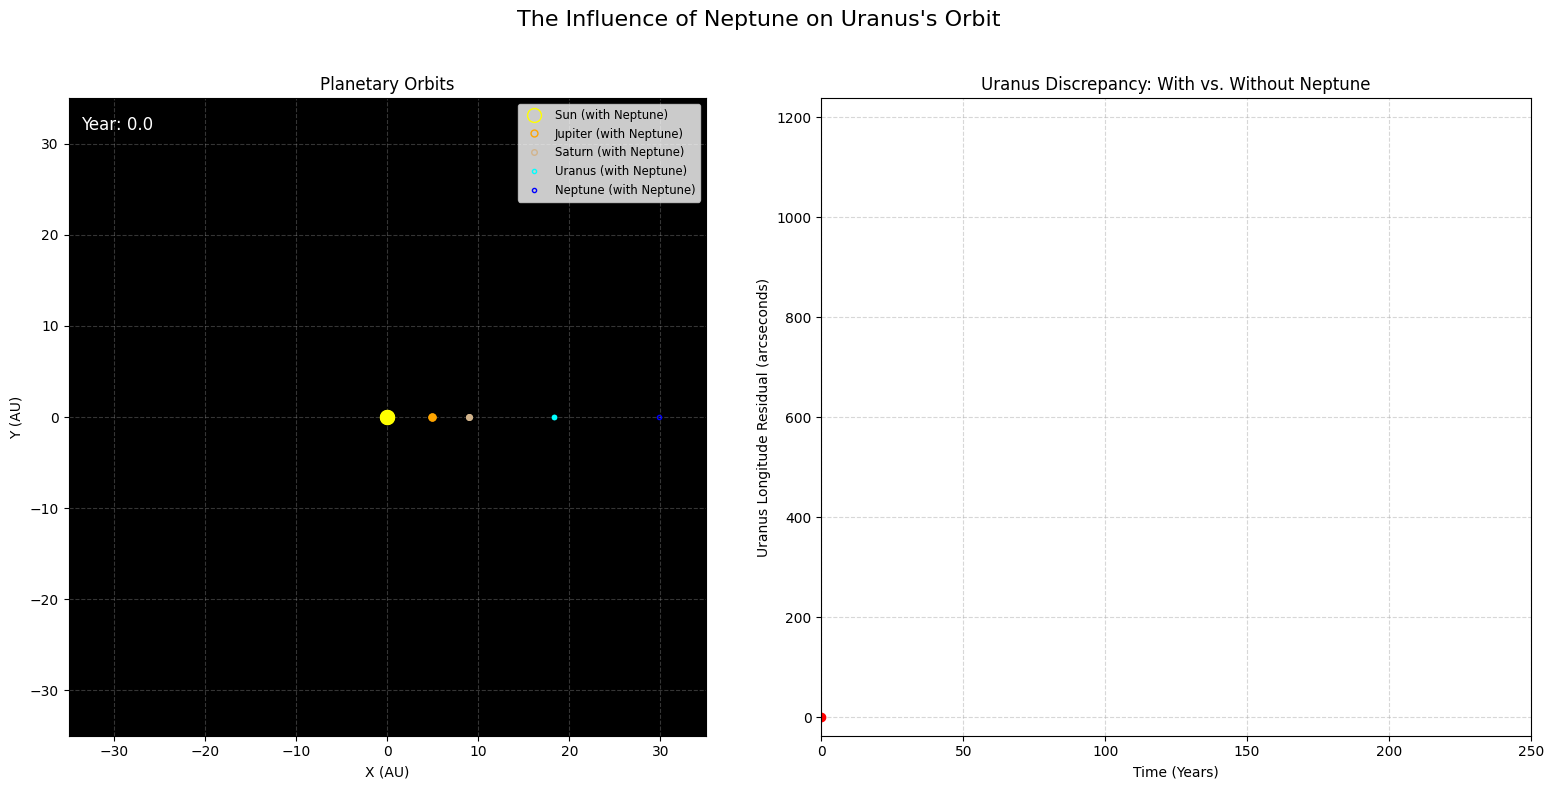

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# --- Constants ---
G = 6.67430e-11  # Gravitational constant (m^3 kg^-1 s^-2) -> scaled for AU/days
G_SCALED = 2.959e-4  # G in AU^3 / (M_sun * day^2)
M_SUN = 1.989e30 # kg

# --- Planet Data ---
# Data format: [mass (in solar masses), semi-major axis (AU), eccentricity, orbital period (days), color]
# Orbital data is approximate for this toy model.
PLANETS_A = {
    'Sun': [1.0, 0, 0, 0, 'yellow'],
    'Jupiter': [9.547e-4, 5.203, 0.048, 4332, 'orange'],
    'Saturn': [2.858e-4, 9.537, 0.054, 10759, 'tan'],
    'Uranus': [4.366e-5, 19.191, 0.047, 30688, 'cyan']
}

PLANETS_B = {
    'Sun': [1.0, 0, 0, 0, 'yellow'],
    'Jupiter': [9.547e-4, 5.203, 0.048, 4332, 'orange'],
    'Saturn': [2.858e-4, 9.537, 0.054, 10759, 'tan'],
    'Uranus': [4.366e-5, 19.191, 0.047, 30688, 'cyan'],
    'Neptune': [5.151e-5, 30.069, 0.008, 60182, 'blue']
}

class NBodySimulation:
    """
    A class to handle the N-body simulation using velocity-Verlet integration.
    """
    def __init__(self, bodies_data):
        self.bodies_data = bodies_data
        self.num_bodies = len(bodies_data)
        self.names = list(bodies_data.keys())
        self.masses = np.array([data[0] for data in bodies_data.values()]).reshape(self.num_bodies, 1)
        self.colors = [data[4] for data in bodies_data.values()]

        # Initialize positions and velocities
        self.positions = np.zeros((self.num_bodies, 2))
        self.velocities = np.zeros((self.num_bodies, 2))

        for i, (name, data) in enumerate(bodies_data.items()):
            if name == 'Sun':
                continue
            a = data[1] # semi-major axis
            e = data[2] # eccentricity
            # Start at perihelion for simplicity
            self.positions[i, 0] = a * (1 - e)
            # Velocity at perihelion: v = sqrt( (G*M_sun/a) * (1+e)/(1-e) )
            self.velocities[i, 1] = np.sqrt(G_SCALED * self.masses[0] * (1 + e) / (a * (1 - e)))

    def calculate_accelerations(self):
        """Calculates acceleration on each body due to gravitational forces from all others."""
        accelerations = np.zeros_like(self.positions)
        for i in range(self.num_bodies):
            for j in range(self.num_bodies):
                if i == j:
                    continue
                # Vector from body i to body j
                r_ij = self.positions[j] - self.positions[i]
                # Distance squared
                dist_sq = np.sum(r_ij**2)
                # Magnitude of distance
                dist = np.sqrt(dist_sq)
                # Gravitational force formula component
                force_mag = G_SCALED * self.masses[j] / (dist_sq * dist)
                # Accumulate acceleration
                accelerations[i] += force_mag * r_ij
        return accelerations

    def update(self, dt):
        """
        Updates positions and velocities using the velocity-Verlet algorithm.
        """
        # Initial half-step for velocity
        accelerations = self.calculate_accelerations()
        self.velocities += 0.5 * accelerations * dt

        # Full-step for position
        self.positions += self.velocities * dt

        # Calculate new accelerations at the new position
        new_accelerations = self.calculate_accelerations()

        # Final half-step for velocity
        self.velocities += 0.5 * new_accelerations * dt

def run_simulation():
    """
    Runs the full simulation for both scenarios and prepares data for plotting.
    """
    # Simulation parameters
    dt = 50.0  # Time step in days
    years = 250
    steps = int(years * 365.25 / dt)

    # Initialize simulations
    sim_A = NBodySimulation(PLANETS_A) # Without Neptune
    sim_B = NBodySimulation(PLANETS_B) # With Neptune

    # Store history for plotting
    history_A = np.zeros((steps, sim_A.num_bodies, 2))
    history_B = np.zeros((steps, sim_B.num_bodies, 2))

    # Run integration loop
    for i in range(steps):
        history_A[i] = sim_A.positions
        history_B[i] = sim_B.positions
        sim_A.update(dt)
        sim_B.update(dt)

    return history_A, history_B, dt, years

# --- Run the simulation to get data ---
history_A, history_B, dt, total_years = run_simulation()

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle("The Influence of Neptune on Uranus's Orbit", fontsize=16)

# --- Panel 1: Orbit Animation ---
ax1.set_aspect('equal')
ax1.set_xlim(-35, 35)
ax1.set_ylim(-35, 35)
ax1.set_facecolor('black')
ax1.set_xlabel('X (AU)')
ax1.set_ylabel('Y (AU)')
ax1.set_title('Planetary Orbits')
ax1.grid(True, linestyle='--', alpha=0.3)

# Placeholders for animated elements
paths_A = [ax1.plot([], [], '-', color=c, linewidth=0.5, alpha=0.7)[0] for c in NBodySimulation(PLANETS_A).colors]
planets_A = [ax1.plot([], [], 'o', color=c, markersize=ms)[0] for c, ms in zip(NBodySimulation(PLANETS_A).colors, [10, 5, 4, 3])]
planets_B = [ax1.plot([], [], 'o', color=c, markersize=ms, markerfacecolor='none', markeredgewidth=1.0)[0] for c, ms in zip(NBodySimulation(PLANETS_B).colors, [10, 5, 4, 3, 3])]
legend_labels = list(PLANETS_B.keys())
ax1.legend(planets_B, [f"{name} (with Neptune)" for name in legend_labels], loc='upper right', fontsize='small')

time_text = ax1.text(0.02, 0.95, '', transform=ax1.transAxes, color='white', fontsize=12)

# --- Panel 2: Longitude Residual Plot ---
uranus_index_A = list(PLANETS_A.keys()).index('Uranus')
uranus_index_B = list(PLANETS_B.keys()).index('Uranus')

# Calculate angular position (longitude) for Uranus in both simulations
lon_A = np.arctan2(history_A[:, uranus_index_A, 1], history_A[:, uranus_index_A, 0])
lon_B = np.arctan2(history_B[:, uranus_index_B, 1], history_B[:, uranus_index_B, 0])

# Unwrap angle to handle the jump from +pi to -pi
lon_A = np.unwrap(lon_A)
lon_B = np.unwrap(lon_B)

# Calculate the residual in arcseconds (1 radian = 206265 arcseconds)
residuals = (lon_B - lon_A) * 206265
time_years = np.arange(0, total_years, dt / 365.25)

ax2.set_xlim(0, total_years)
ax2.set_ylim(min(residuals) * 1.1, max(residuals) * 1.1)
ax2.set_xlabel('Time (Years)')
ax2.set_ylabel('Uranus Longitude Residual (arcseconds)')
ax2.set_title('Uranus Discrepancy: With vs. Without Neptune')
ax2.grid(True, linestyle='--', alpha=0.5)
residual_line, = ax2.plot([], [], 'r-')
residual_point, = ax2.plot([], [], 'ro') # To mark the current time


def animate(i):
    """Animation function, called for each frame."""
    frame_skip = 10 # Speed up animation
    frame_idx = i * frame_skip
    if frame_idx >= len(history_A):
        # When using blit=True, it's important to return an iterable of artists.
        # An empty list is fine if no updates are made.
        return []

    # Update orbits plot
    for j in range(len(paths_A)):
        paths_A[j].set_data(history_A[:frame_idx, j, 0], history_A[:frame_idx, j, 1])
        # For single points, set_data expects a sequence (like a list) for x and y
        planets_A[j].set_data([history_A[frame_idx, j, 0]], [history_A[frame_idx, j, 1]])

    for j in range(len(planets_B)):
        planets_B[j].set_data([history_B[frame_idx, j, 0]], [history_B[frame_idx, j, 1]])

    year = time_years[frame_idx]
    time_text.set_text(f'Year: {year:.1f}')

    # Update residuals plot
    residual_line.set_data(time_years[:frame_idx], residuals[:frame_idx])
    residual_point.set_data([time_years[frame_idx]], [residuals[frame_idx]])

    return paths_A + planets_A + planets_B + [time_text, residual_line, residual_point]


# Create the animation
num_frames = len(history_A) // 10
ani = FuncAnimation(fig, animate, frames=num_frames, interval=20, blit=True, repeat=False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()